# Dimensionnement du marché : combien de TPE-PME Duo Facture peut-elle viser ?

**Auteure :** Niya C. Danielle Ouattara

**Question :** combien d'entreprises sont concernées par la réforme, combien sont réellement accessibles pour une nouvelle offre, et quel objectif de clients est réaliste à trois ans ?

| Niveau | Définition retenue |
|---|---|
| **TAM** (marché total) | Toutes les microentreprises et PME françaises, concernées par la réforme |
| **SAM** (marché accessible) | Les entreprises sans solution de facturation, qui doivent s'équiper |
| **SOM** (marché atteignable) | La part du SAM qu'une nouvelle offre peut conquérir en trois ans |

**Sources**
- Insee, Ésane, *Caractéristiques des entreprises par catégorie, données 2023* (publié le 18/09/2025), champ : secteurs marchands non agricoles et non financiers. https://www.insee.fr/fr/statistiques/2016091
- Baromètre France Num 2022 : taux d'équipement et segments, calculés dans `01_voix_du_client.ipynb`.

## 1. Le marché total (TAM)

In [1]:
import pandas as pd                      # pandas : la bibliothèque qui manipule des tableaux
import matplotlib.pyplot as plt          # matplotlib : la bibliothèque qui dessine les graphiques

entreprises = pd.Series({                # nombre d'entreprises en France en 2023 (Insee, Ésane)
    "Microentreprises": 4_831_709,       # moins de 10 salariés et chiffre d'affaires ou bilan de 2 M€ ou moins
    "PME hors microentreprises": 172_520,   # de 10 à 249 salariés
})

tam = entreprises.sum()                  # le TAM : toutes les microentreprises et PME
print(f"TAM : {tam:,.0f} entreprises".replace(",", " "))   # affiche le total avec une espace comme séparateur de milliers

TAM : 5 004 229 entreprises


## 2. Le marché accessible (SAM)

On applique au TAM les parts de segments mesurées dans le baromètre France Num. Le cœur de cible de Duo Facture est l'ensemble des entreprises **sans solution de facturation** : elles devront s'équiper avant le 1er septembre 2027.

In [2]:
segments = pd.Series({                   # part pondérée de chaque segment (notebook 01, section 5)
    "Équipées à faire migrer": 0.695,
    "Non équipées prêtes à investir": 0.148,
    "Non équipées à budget serré": 0.157,
})

volumes = (segments * tam).round(-3)     # nombre d'entreprises par segment, arrondi au millier
print(volumes.map(lambda v: f"{v:,.0f}".replace(",", " ")))   # affiche chaque volume avec une espace comme séparateur

sam = volumes["Non équipées prêtes à investir"] + volumes["Non équipées à budget serré"]   # le SAM : les deux segments non équipés
print(f"SAM : {sam:,.0f} entreprises".replace(",", " "))

Équipées à faire migrer           3 478 000
Non équipées prêtes à investir      741 000
Non équipées à budget serré         786 000
dtype: str
SAM : 1 527 000 entreprises


## 3. Le marché atteignable (SOM)

Le SOM repose sur deux hypothèses explicites, à ajuster selon les moyens de l'éditeur :
- **Part de conquête à trois ans** : 1 % (prudent), 2 % (central), 3 % (ambitieux) du SAM, auxquels s'ajoutent 0,2 % des entreprises équipées qui changeraient d'outil.
- **Revenu moyen par client** : il découle de la grille de prix (`docs/pricing_packaging.md`). L'offre d'entrée est gratuite, comme chez la plupart des concurrents ; on suppose 60 % de clients en Découverte (0 €), 30 % en Essentiel (9 € HT par mois) et 10 % en Accompagné (19 € HT par mois).

In [3]:
grille = pd.DataFrame({"Prix mensuel HT": [0, 9, 19],              # prix de chaque offre, en euros
                      "Part des clients": [0.60, 0.30, 0.10]},  # répartition supposée des clients
                     index=["Découverte", "Essentiel", "Accompagné"])
arpu = (grille["Prix mensuel HT"] * grille["Part des clients"]).sum()   # revenu moyen par client et par mois (ARPU)
prix_annuel = arpu * 12                  # revenu moyen par client et par an
print(f"Revenu moyen par client : {arpu:.2f} € HT par mois")
part_migration = 0.002                   # hypothèse : 0,2 % des entreprises équipées passent à Duo Facture

scenarios = pd.DataFrame({"Part du SAM conquise": [0.01, 0.02, 0.03]},   # trois scénarios de conquête
                         index=["Prudent", "Central", "Ambitieux"])
scenarios["Clients non équipés"] = scenarios["Part du SAM conquise"] * sam                  # clients issus du SAM
scenarios["Clients migrés"] = part_migration * volumes["Équipées à faire migrer"]           # clients venant d'un autre outil
scenarios["Clients total"] = scenarios["Clients non équipés"] + scenarios["Clients migrés"] # total de clients
scenarios["Revenu annuel (M€)"] = scenarios["Clients total"] * prix_annuel / 1e6            # revenu récurrent annuel, en millions d'euros
scenarios.round({"Part du SAM conquise": 2, "Clients non équipés": 0, "Clients migrés": 0,   # arrondis adaptés à chaque colonne
                 "Clients total": 0, "Revenu annuel (M€)": 1})

Revenu moyen par client : 4.60 € HT par mois


,Part du SAM conquise,Clients non équipés,Clients migrés,Clients total,Revenu annuel (M€)
Prudent,0.01,15270.0,6956.0,22226.0,1.2
Central,0.02,30540.0,6956.0,37496.0,2.1
Ambitieux,0.03,45810.0,6956.0,52766.0,2.9


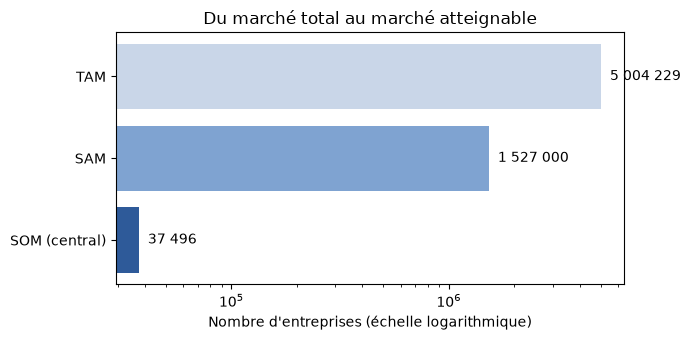

In [4]:
niveaux = pd.Series({                    # les trois niveaux, pour le graphique
    "TAM": tam,
    "SAM": sam,
    "SOM (central)": scenarios.loc["Central", "Clients total"],
})

fig, ax = plt.subplots(figsize=(7, 3.5))                       # zone de dessin
ax.barh(niveaux.index, niveaux.values, color=["#C9D6E8", "#7FA3D1", "#2E5A99"])   # une barre par niveau, du plus clair au plus foncé
ax.set_xscale("log")                                           # échelle logarithmique : les trois niveaux sont très différents
ax.invert_yaxis()                                              # TAM en haut
ax.set_xlabel("Nombre d'entreprises (échelle logarithmique)")
ax.set_title("Du marché total au marché atteignable")
for i, v in enumerate(niveaux.values):                         # pour chaque barre
    ax.text(v * 1.1, i, f"{v:,.0f}".replace(",", " "), va="center")   # écrit le volume au bout de la barre
plt.tight_layout()
plt.show()

## 4. Conclusion

1. **Le marché total compte environ 5 millions de microentreprises et PME**, toutes concernées par la réforme.
2. **Le marché accessible représente environ 1,5 million d'entreprises** sans solution de facturation, réparties presque à parts égales entre celles qui sont prêtes à investir et celles qui ont un budget serré.
3. **Dans le scénario central**, Duo Facture vise environ 37 500 clients à trois ans, pour environ 2,1 M€ de revenu récurrent annuel. Ce montant reste modeste parce que l'offre d'entrée est gratuite : le revenu dépend avant tout de la part de clients qui passent à une offre payante.

**Limites**
- Le champ Insee exclut l'agriculture et la finance, alors que le baromètre les inclut. Les parts de segments sont appliquées telles quelles.
- Les microentreprises comprennent des micro-entrepreneurs dont une partie n'a pas d'activité régulière : le SAM réellement actif est probablement plus faible.
- Les taux d'équipement datent de 2022 : une partie des entreprises s'est équipée depuis, à l'approche de la réforme.